# Bangla-English Code-Mixed Sentiment Classification
**Bag-of-Words vs TF-IDF** with Naive Bayes, Logistic Regression and SVM

Python port of `Banglish_Sentiment_test.R`.

**Pipeline:** Data Collection → Exploration → Preprocessing → BoW & TF-IDF → Train/Test Split → Classification → Evaluation → Confusion Matrices → Comparison → Interpretation

**Dataset:** `Banglish_Dataset.csv` (columns: `text`, `sentiment`)

## 0. Setup

In [4]:
# Run once if a package is missing
# %pip install -q numpy pandas scipy scikit-learn matplotlib seaborn wordcloud

In [5]:
import re
import unicodedata
from collections import Counter

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import BernoulliNB
from sklearn.linear_model import LogisticRegressionCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix)

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

## 1. Data Collection

In [6]:
# Update this path if the CSV lives elsewhere (Colab: upload the file, then use "Banglish_Dataset.csv")
DATA_PATH = r"E:\project\ml\Bangla-English Code-Mixed Sentiment Classification\Banglish_Dataset.csv"

# utf-8-sig strips a leading byte-order-mark if present
df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
df.columns = [c.lstrip("\ufeff") for c in df.columns]

assert {"text", "sentiment"}.issubset(df.columns), "CSV must contain 'text' and 'sentiment' columns"

# Drop rows with missing text/labels, then exact duplicate texts
df = df[df["text"].notna() & df["sentiment"].notna() & (df["text"].astype(str).str.strip() != "")]
df = df.drop_duplicates(subset="text", keep="first").reset_index(drop=True)

# Standardise labels
df["sentiment"] = df["sentiment"].astype(str).str.strip().str.lower()

print("=" * 53)
print("STEP 1: DATA COLLECTION")
print("=" * 53)
print("Rows loaded (after cleaning duplicates/blank rows):", len(df))
print("Columns:", ", ".join(df.columns), "\n")
df.head()

STEP 1: DATA COLLECTION
Rows loaded (after cleaning duplicates/blank rows): 25000
Columns: text, sentiment 



,text,sentiment
0,boss er eta to masti chiloooo 🥳,positive
1,assignment ta mone hoy average choltese,neutral
2,Bossssss er moderate thaake,neutral
3,bus e ekdom boring atke gelam ❌,negative
4,Traffic ta khub moderate kora hoy nai 😂,neutral


## 2. Dataset Exploration

In [7]:
print("=" * 53)
print("STEP 2: DATASET EXPLORATION")
print("=" * 53)

print("Class distribution:")
print(df["sentiment"].value_counts().sort_index())
print((df["sentiment"].value_counts(normalize=True).sort_index() * 100).round(2))

# Text length in words
df["word_count"] = df["text"].str.count(r"\S+")
print("\nWord-count summary:")
print(df["word_count"].describe())

STEP 2: DATASET EXPLORATION
Class distribution:
sentiment
negative    8434
neutral     8042
positive    8524
Name: count, dtype: int64
sentiment
negative    33.74
neutral     32.17
positive    34.10
Name: proportion, dtype: float64

Word-count summary:
count    25000.000000
mean         6.602000
std          1.403366
min          3.000000
25%          6.000000
50%          7.000000
75%          8.000000
max         12.000000
Name: word_count, dtype: float64


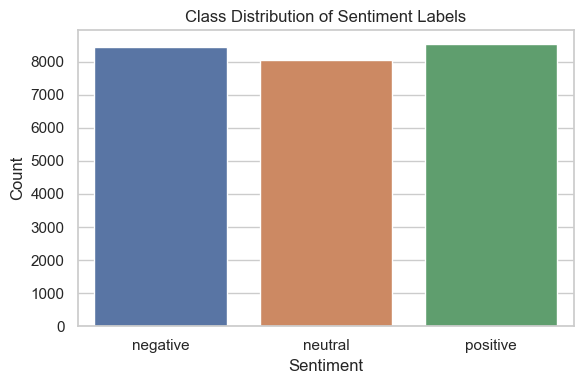

In [8]:
# Plot 1: class distribution
fig, ax = plt.subplots(figsize=(6, 4))
order = sorted(df["sentiment"].unique())
sns.countplot(data=df, x="sentiment", order=order, hue="sentiment", hue_order=order,
              legend=False, ax=ax)
ax.set(title="Class Distribution of Sentiment Labels", xlabel="Sentiment", ylabel="Count")
plt.tight_layout()
plt.savefig("plot_class_distribution.png", dpi=150)
plt.show()

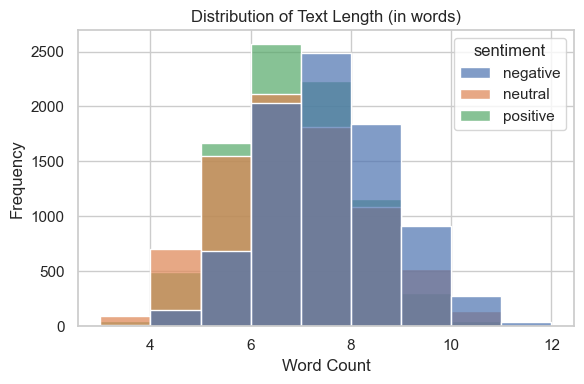

In [9]:
# Plot 2: word-count distribution
fig, ax = plt.subplots(figsize=(6, 4))
sns.histplot(data=df, x="word_count", hue="sentiment", hue_order=order, binwidth=1,
             multiple="layer", alpha=0.7, ax=ax)
ax.set(title="Distribution of Text Length (in words)", xlabel="Word Count", ylabel="Frequency")
plt.tight_layout()
plt.savefig("plot_wordcount_distribution.png", dpi=150)
plt.show()

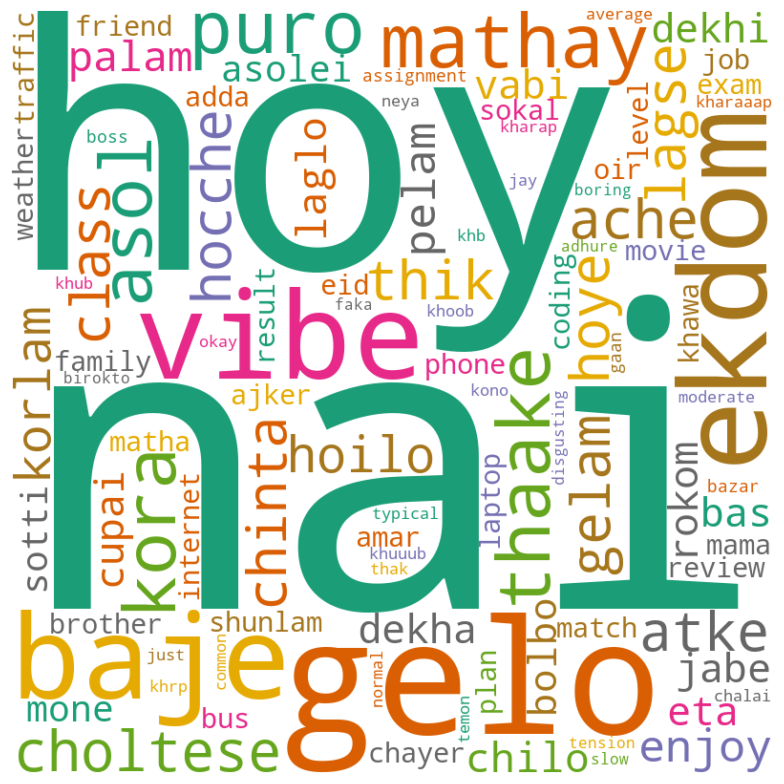


Exploration plots saved: plot_class_distribution.png, plot_wordcount_distribution.png, plot_wordcloud.png


In [10]:
# Plot 3: word cloud (quick lowercase/letters-only pass; full cleaning happens in Step 3)
def quick_clean(s: str) -> str:
    s = s.lower()
    s = re.sub(r"[^a-z\s]", " ", s)
    return " ".join(s.split())

quick = df["text"].astype(str).map(quick_clean)
word_freq = Counter(w for t in quick for w in t.split())
word_freq = {w: c for w, c in word_freq.items() if len(w) > 2}   # drop 1-2 letter noise

wc = WordCloud(width=800, height=800, background_color="white", max_words=100,
               colormap="Dark2", random_state=SEED).generate_from_frequencies(word_freq)

plt.figure(figsize=(8, 8))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.tight_layout()
plt.savefig("plot_wordcloud.png", dpi=150)
plt.show()

print("\nExploration plots saved: plot_class_distribution.png, plot_wordcount_distribution.png, plot_wordcloud.png")

## 3. Text Preprocessing
Cleaning, normalisation, tokenisation and stopword handling for Banglish (romanised Bangla + English) text:
- strip emojis / non-ASCII symbols
- remove URLs, mentions, `#` symbols
- keep letters only, lowercase
- collapse 3+ repeated letters (`boringgggg` → `boringg`)
- remove English + Banglish stopwords

In [11]:
print("=" * 53)
print("STEP 3: TEXT PREPROCESSING")
print("=" * 53)

def clean_text(text: str) -> str:
    # strip emojis/non-ASCII (transliterate accents where possible, drop the rest)
    text = unicodedata.normalize("NFKD", str(text)).encode("ascii", "ignore").decode("ascii")
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", " ", text)     # URLs
    text = re.sub(r"@\w+", " ", text)                # mentions
    text = text.replace("#", " ")                    # hashtag symbol
    text = re.sub(r"[^a-z\s]", " ", text)            # letters only
    text = re.sub(r"(.)\1{2,}", r"\1\1", text)       # 3+ repeats -> 2
    return " ".join(text.split())                    # squish whitespace

df["clean_text"] = df["text"].map(clean_text)

# Remove rows that became empty after cleaning
df = df[df["clean_text"].str.strip() != ""].reset_index(drop=True)

print("Example of raw vs cleaned text:")
display(df[["text", "clean_text"]].head(5))

STEP 3: TEXT PREPROCESSING
Example of raw vs cleaned text:


,text,clean_text
0,boss er eta to masti chiloooo 🥳,boss er eta to masti chiloo
1,assignment ta mone hoy average choltese,assignment ta mone hoy average choltese
2,Bossssss er moderate thaake,boss er moderate thaake
3,bus e ekdom boring atke gelam ❌,bus e ekdom boring atke gelam
4,Traffic ta khub moderate kora hoy nai 😂,traffic ta khub moderate kora hoy nai


In [12]:
# English stopwords (same list R's tm::stopwords("english") uses)
english_stopwords = set('''
i me my myself we our ours ourselves you your yours yourself yourselves he him his himself
she her hers herself it its itself they them their theirs themselves what which who whom
this that these those am is are was were be been being have has had having do does did doing
would should could ought i'm you're he's she's it's we're they're i've you've we've they've
i'd you'd he'd she'd we'd they'd i'll you'll he'll she'll we'll they'll isn't aren't wasn't
weren't hasn't haven't hadn't doesn't don't didn't won't wouldn't shan't shouldn't can't
cannot couldn't mustn't let's that's who's what's here's there's when's where's why's how's
a an the and but if or because as until while of at by for with about against between into
through during before after above below to from up down in out on off over under again
further then once here there when where why how all any both each few more most other some
such no nor not only own same so than too very
'''.split())

# Common romanised-Bangla function words/particles with little sentiment signal
banglish_stopwords = {
    "ta", "er", "e", "ei", "oi", "amar", "ami", "tumi", "apni", "se",
    "amra", "tara", "eta", "oita", "ekta", "hoy", "hoyeche", "hocche",
    "hoise", "korte", "kore", "korlam", "koreche", "hobe", "chilo",
    "hote", "diye", "niye", "jabo", "gelo", "gelam", "asche", "ache",
    "nai", "na", "ekhon", "ekdom", "sotti", "onek", "khub",
}

ALL_STOPWORDS = english_stopwords | banglish_stopwords

def remove_stopwords(text: str) -> str:
    return " ".join(w for w in text.split() if w not in ALL_STOPWORDS)

df["tokens"] = df["clean_text"].map(remove_stopwords)
print("Tokenisation & stopword removal complete.")
df[["clean_text", "tokens"]].head()

Tokenisation & stopword removal complete.


,clean_text,tokens
0,boss er eta to masti chiloo,boss masti chiloo
1,assignment ta mone hoy average choltese,assignment mone average choltese
2,boss er moderate thaake,boss moderate thaake
3,bus e ekdom boring atke gelam,bus boring atke
4,traffic ta khub moderate kora hoy nai,traffic moderate kora


## 4. Feature Representation: Bag-of-Words and TF-IDF

Mirrors R's `tm` behaviour:
- unigrams of length ≥ 2, term must appear in ≥ 3 documents
- `removeSparseTerms(0.995)`: keep terms present in more than 0.5 % of documents
- TF-IDF = `(count / doc_length) × log2(N / df)` (the same formula as `tm::weightTfIdf(normalize = TRUE)`)

In [13]:
print("=" * 53)
print("STEP 4: FEATURE REPRESENTATION (BoW & TF-IDF)")
print("=" * 53)

# Raw counts; term must appear in >= 3 docs; tokens of 2+ letters
cv = CountVectorizer(token_pattern=r"(?u)\b[a-z]{2,}\b", min_df=3, lowercase=False)
counts = cv.fit_transform(df["tokens"]).tocsr().astype(np.float64)
vocab = np.array(cv.get_feature_names_out())
n_docs = counts.shape[0]

# --- TF-IDF (computed on the min_df-filtered matrix, like tm) ---
doc_len = np.asarray(counts.sum(axis=1)).ravel()
doc_len[doc_len == 0] = 1.0                                   # empty rows stay all-zero
tf = sp.diags(1.0 / doc_len) @ counts
doc_freq = np.asarray((counts > 0).sum(axis=0)).ravel()
idf = np.log2(n_docs / doc_freq)
tfidf = (tf @ sp.diags(idf)).tocsr()

# --- removeSparseTerms(0.995): keep terms with df > N * (1 - 0.995) ---
keep_terms = doc_freq > n_docs * (1 - 0.995)
X_bow_full = counts[:, keep_terms].tocsr()
X_tfidf_full = tfidf[:, keep_terms].tocsr()
vocab = vocab[keep_terms]

print("BoW matrix dimensions   :", " x ".join(map(str, X_bow_full.shape)))
print("TF-IDF matrix dimensions:", " x ".join(map(str, X_tfidf_full.shape)), "\n")

# Drop all-zero rows (e.g. messages made only of stopwords)
keep_rows = (np.asarray(X_bow_full.sum(axis=1)).ravel() > 0) & \
            (np.asarray(X_tfidf_full.sum(axis=1)).ravel() > 0)

X_bow = X_bow_full[keep_rows]
X_tfidf = X_tfidf_full[keep_rows]
labels = df.loc[keep_rows, "sentiment"].reset_index(drop=True)
classes = sorted(labels.unique())

print("Documents retained after removing zero-vector rows:", int(keep_rows.sum()),
      f"(dropped {int((~keep_rows).sum())})\n")

STEP 4: FEATURE REPRESENTATION (BoW & TF-IDF)
BoW matrix dimensions   : 25000 x 138
TF-IDF matrix dimensions: 25000 x 138 

Documents retained after removing zero-vector rows: 24992 (dropped 8)



## 5. Train-Test Split (80 / 20, stratified)

In [14]:
print("=" * 53)
print("STEP 5: TRAIN-TEST SPLIT")
print("=" * 53)

idx = np.arange(len(labels))
train_idx, test_idx = train_test_split(idx, test_size=0.2, stratify=labels, random_state=SEED)

y_train, y_test = labels.iloc[train_idx].values, labels.iloc[test_idx].values

X_bow_train, X_bow_test = X_bow[train_idx], X_bow[test_idx]
X_tfidf_train, X_tfidf_test = X_tfidf[train_idx], X_tfidf[test_idx]

print("Training set size:", X_bow_train.shape[0])
print("Test set size    :", X_bow_test.shape[0])
print("Feature counts -> BoW:", X_bow_train.shape[1], "| TF-IDF:", X_tfidf_train.shape[1], "\n")

STEP 5: TRAIN-TEST SPLIT
Training set size: 19993
Test set size    : 4999
Feature counts -> BoW: 138 | TF-IDF: 138 



## 6. Classification Models

| R | Python |
|---|---|
| `e1071::naiveBayes` on binarised 0/1 features, `laplace = 1` | `BernoulliNB(alpha=1)` |
| `cv.glmnet` multinomial lasso, 5-fold, `lambda.min` | `LogisticRegressionCV` (L1, multinomial, 5-fold) on standardised features |
| `e1071::svm` linear kernel, `cost = 1`, `scale = FALSE` | `SVC(kernel="linear", C=1)` |

> `glmnet` uses a *grouped* lasso across classes, which scikit-learn does not offer. The plain L1 multinomial model is the closest equivalent, so LR numbers can differ slightly from R.

In [15]:
def run_naive_bayes(X_train, y_train, X_test):
    # Presence/absence features + Laplace smoothing (Bernoulli NB)
    model = BernoulliNB(alpha=1.0, binarize=0.0)
    model.fit(X_train, y_train)
    return model, model.predict(X_test)


def run_logistic_regression(X_train, y_train, X_test):
    # glmnet standardises predictors by default -> scale (no centering keeps sparsity)
    model = make_pipeline(
        StandardScaler(with_mean=False),
        LogisticRegressionCV(
            Cs=np.logspace(-3, 1, 12), cv=5, penalty="l1", solver="saga",
            scoring="neg_log_loss", max_iter=300, tol=1e-3,
            n_jobs=-1, random_state=SEED,
        ),
    )
    model.fit(X_train, y_train)
    return model, model.predict(X_test)


def run_svm(X_train, y_train, X_test):
    model = SVC(kernel="linear", C=1.0, probability=False)
    model.fit(X_train, y_train)
    return model, model.predict(X_test)


def compute_metrics(preds, actual):
    """Accuracy + macro Precision / Recall / F1 + confusion matrix (rows = Prediction, cols = Reference, as in caret)."""
    p, r, f1, _ = precision_recall_fscore_support(
        actual, preds, labels=classes, average="macro", zero_division=0
    )
    cm = confusion_matrix(actual, preds, labels=classes).T       # transpose -> caret layout
    cm_df = pd.DataFrame(cm, index=pd.Index(classes, name="Prediction"),
                         columns=pd.Index(classes, name="Reference"))
    return {
        "confusion_matrix": cm_df,
        "accuracy": accuracy_score(actual, preds),
        "precision": p,
        "recall": r,
        "f1": f1,
    }

In [16]:
print("=" * 53)
print("STEP 6: CLASSIFICATION")
print("=" * 53)

feature_sets = {
    "BoW":   {"train": X_bow_train,   "test": X_bow_test},
    "TFIDF": {"train": X_tfidf_train, "test": X_tfidf_test},
}

results = {}

for feat_name, fs in feature_sets.items():
    print("-" * 51)
    print("Feature representation:", feat_name)
    print("-" * 51)
    Xtr, Xte = fs["train"], fs["test"]

    print("Training Naive Bayes...")
    _, nb_preds = run_naive_bayes(Xtr, y_train, Xte)

    print("Training Logistic Regression (L1, multinomial, 5-fold CV)...")
    _, lr_preds = run_logistic_regression(Xtr, y_train, Xte)

    print("Training SVM (linear kernel)...")
    _, svm_preds = run_svm(Xtr, y_train, Xte)

    results[feat_name] = {
        "NaiveBayes":         compute_metrics(nb_preds, y_test),
        "LogisticRegression": compute_metrics(lr_preds, y_test),
        "SVM":                compute_metrics(svm_preds, y_test),
    }
    print("Finished models for", feat_name, "\n")

STEP 6: CLASSIFICATION
---------------------------------------------------
Feature representation: BoW
---------------------------------------------------
Training Naive Bayes...
Training Logistic Regression (L1, multinomial, 5-fold CV)...


c:\python\Lib\site-packages\sklearn\linear_model\_logistic.py:1780: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
c:\python\Lib\site-packages\sklearn\linear_model\_logistic.py:1811: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' instead. Use l1_ratios=(0,) instead of penalty='l2'  and l1_ratios=(1,) instead of penalty='l1'.
  warnings.warn(
c:\python\Lib\site-packages\sklearn\linear_model\_logistic.py:1823: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this war

Training SVM (linear kernel)...
Finished models for BoW 

---------------------------------------------------
Feature representation: TFIDF
---------------------------------------------------
Training Naive Bayes...
Training Logistic Regression (L1, multinomial, 5-fold CV)...


c:\python\Lib\site-packages\sklearn\linear_model\_logistic.py:1780: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
c:\python\Lib\site-packages\sklearn\linear_model\_logistic.py:1811: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' instead. Use l1_ratios=(0,) instead of penalty='l2'  and l1_ratios=(1,) instead of penalty='l1'.
  warnings.warn(
c:\python\Lib\site-packages\sklearn\linear_model\_logistic.py:1823: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this war

Training SVM (linear kernel)...
Finished models for TFIDF 



## 7. Evaluation Summary (Accuracy, Precision, Recall, F1)

In [17]:
print("=" * 53)
print("STEP 7: EVALUATION SUMMARY")
print("=" * 53)

rows = []
for feat_name, models in results.items():
    for model_name, m in models.items():
        rows.append({
            "Feature": feat_name,
            "Model": model_name,
            "Accuracy": round(m["accuracy"], 4),
            "Precision": round(m["precision"], 4),
            "Recall": round(m["recall"], 4),
            "F1": round(m["f1"], 4),
        })
summary_df = pd.DataFrame(rows)

print("Model performance summary:")
display(summary_df)
summary_df.to_csv("model_performance_summary.csv", index=False)
print("\nSaved: model_performance_summary.csv")

STEP 7: EVALUATION SUMMARY
Model performance summary:


,Feature,Model,Accuracy,Precision,Recall,F1
0,BoW,NaiveBayes,0.9922,0.9922,0.9921,0.9922
1,BoW,LogisticRegression,0.9970,0.9970,0.9970,0.9970
2,BoW,SVM,0.9970,0.9969,0.9970,0.9970
3,TFIDF,NaiveBayes,0.9922,0.9922,0.9921,0.9922
4,TFIDF,LogisticRegression,0.9968,0.9968,0.9968,0.9968
5,TFIDF,SVM,0.9970,0.9970,0.9970,0.9970



Saved: model_performance_summary.csv


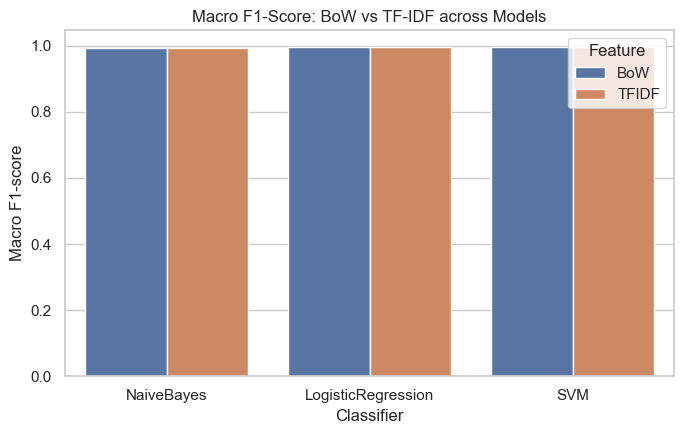

Saved: plot_model_comparison_f1.png


In [18]:
# Macro F1: BoW vs TF-IDF across models
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(data=summary_df, x="Model", y="F1", hue="Feature", ax=ax)
ax.set(title="Macro F1-Score: BoW vs TF-IDF across Models", xlabel="Classifier", ylabel="Macro F1-score")
plt.tight_layout()
plt.savefig("plot_model_comparison_f1.png", dpi=150)
plt.show()
print("Saved: plot_model_comparison_f1.png")

## 8. Confusion Matrices

In [19]:
print("=" * 53)
print("STEP 8: CONFUSION MATRICES")
print("=" * 53)

for feat_name, models in results.items():
    for model_name, m in models.items():
        print(f"\n--- {feat_name} - {model_name} ---")
        display(m["confusion_matrix"])

STEP 8: CONFUSION MATRICES

--- BoW - NaiveBayes ---


Reference,negative,neutral,positive
Prediction,,,
negative,1682,0,1
neutral,0,1588,14
positive,5,19,1690



--- BoW - LogisticRegression ---


Reference,negative,neutral,positive
Prediction,,,
negative,1681,0,0
neutral,3,1605,7
positive,3,2,1698



--- BoW - SVM ---


...

Reference,negative,neutral,positive
Prediction,,,
negative,1682,0,1
neutral,0,1588,14
positive,5,19,1690



--- TFIDF - LogisticRegression ---


Reference,negative,neutral,positive
Prediction,,,
negative,1681,2,1
neutral,3,1604,6
positive,3,1,1698



--- TFIDF - SVM ---


Reference,negative,neutral,positive
Prediction,,,
negative,1681,1,3
neutral,3,1605,4
positive,3,1,1698


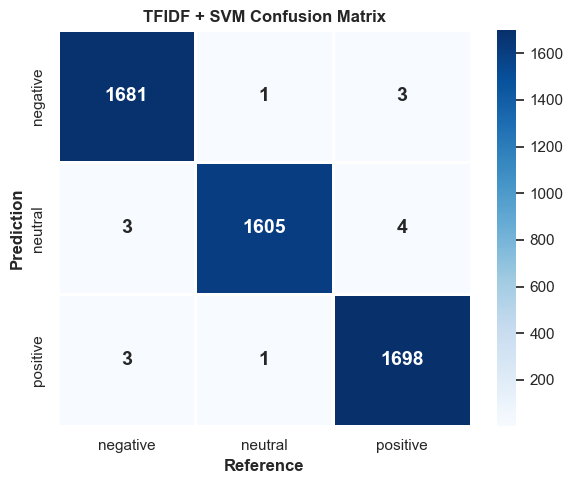

In [20]:
# Heatmap for any configuration (this replaces the hard-coded commented block in the R file)
def plot_confusion_matrix(feat_name="TFIDF", model_name="SVM", save=True):
    cm = results[feat_name][model_name]["confusion_matrix"]      # rows = Prediction, cols = Reference
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", linewidths=1, linecolor="white",
                annot_kws={"size": 14, "weight": "bold"}, cbar=True, ax=ax)
    ax.set_title(f"{feat_name} + {model_name} Confusion Matrix", fontweight="bold")
    ax.set_xlabel("Reference", fontweight="bold")
    ax.set_ylabel("Prediction", fontweight="bold")
    plt.tight_layout()
    if save:
        plt.savefig(f"plot_cm_{feat_name}_{model_name}.png", dpi=150)
    plt.show()

plot_confusion_matrix("TFIDF", "SVM")

## 9. BoW vs TF-IDF and Model Comparison

In [21]:
print("=" * 53)
print("STEP 9: BoW vs TF-IDF AND MODEL COMPARISON")
print("=" * 53)

avg_by_feature = (summary_df.groupby("Feature")
                  .agg(Avg_Accuracy=("Accuracy", "mean"), Avg_F1=("F1", "mean"))
                  .reset_index())
print("Average performance by feature representation:")
display(avg_by_feature)

best_row = summary_df.loc[summary_df["F1"].idxmax()]
print("\nBest performing configuration (by macro F1-score):")
display(best_row.to_frame().T)

STEP 9: BoW vs TF-IDF AND MODEL COMPARISON
Average performance by feature representation:


,Feature,Avg_Accuracy,Avg_F1
0,BoW,0.995400,0.995400
1,TFIDF,0.995333,0.995333



Best performing configuration (by macro F1-score):


,Feature,Model,Accuracy,Precision,Recall,F1
1,BoW,LogisticRegression,0.997,0.997,0.997,0.997


## 10. Result Interpretation

In [22]:
print("=" * 53)
print("STEP 10: RESULT INTERPRETATION")
print("=" * 53)

better_feature = avg_by_feature.loc[avg_by_feature["Avg_F1"].idxmax(), "Feature"]

print(f'''On this Bangla-English code-mixed sentiment dataset ({len(labels)} documents, {len(classes)} classes: {", ".join(classes)}),
'{better_feature}' representation achieved a higher average macro F1-score across the three
classifiers than the alternative representation. The best single configuration
was {best_row["Feature"]} + {best_row["Model"]}, with Accuracy = {best_row["Accuracy"]:.4f} and macro F1 = {best_row["F1"]:.4f}.

Interpretation notes:
  - TF-IDF tends to help when discriminative words (e.g. sentiment-bearing
    Banglish/English tokens such as 'boring', 'moja', 'baje') are down-weighted
    by their frequency across documents, which usually improves linear models
    such as Logistic Regression and SVM.
  - Bag-of-Words (raw counts) can still perform competitively for Naive Bayes,
    since its likelihood formulation is naturally tied to term presence/frequency.
  - Code-mixed, romanised Bangla text is noisy (spelling variation, elongated
    letters, transliteration inconsistency, emojis). The custom cleaning step
    (repeat-letter collapsing, symbol stripping, and a Banglish-aware stopword
    list) was designed to reduce this noise before vectorisation.
  - Class-wise confusion (see Step 8) shows where the model struggles most,
    typically between 'neutral' and either 'positive' or 'negative', which is
    expected given the more subtle linguistic cues for neutral sentiment.

These results should be interpreted as a baseline. Future improvements could
include: subword/character n-gram features (helpful for transliterated text),
word embeddings/fastText trained on Bangla-English text, or transformer-based
multilingual models (e.g. mBERT / XLM-R) fine-tuned on code-mixed corpora.
''')

print("=" * 53)
print("DONE. Outputs saved in the working directory:")
for f in ["plot_class_distribution.png", "plot_wordcount_distribution.png", "plot_wordcloud.png",
          "plot_model_comparison_f1.png", "model_performance_summary.csv"]:
    print(" -", f)
print("=" * 53)

STEP 10: RESULT INTERPRETATION
On this Bangla-English code-mixed sentiment dataset (24992 documents, 3 classes: negative, neutral, positive),
'BoW' representation achieved a higher average macro F1-score across the three
classifiers than the alternative representation. The best single configuration
was BoW + LogisticRegression, with Accuracy = 0.9970 and macro F1 = 0.9970.

Interpretation notes:
  - TF-IDF tends to help when discriminative words (e.g. sentiment-bearing
    Banglish/English tokens such as 'boring', 'moja', 'baje') are down-weighted
    by their frequency across documents, which usually improves linear models
    such as Logistic Regression and SVM.
  - Bag-of-Words (raw counts) can still perform competitively for Naive Bayes,
    since its likelihood formulation is naturally tied to term presence/frequency.
  - Code-mixed, romanised Bangla text is noisy (spelling variation, elongated
    letters, transliteration inconsistency, emojis). The custom cleaning step
    (repe